# Data Preprocessing

In [2]:
import json, time, os, random, shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision.datasets import CIFAR100
from torchvision import transforms as T
from PIL import Image

import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="torch.utils.data.dataloader")

In [ ]:
# Configurations and Seed

SEED = 67
N_TASKS = 10
CLASSES_PER_TASK = 10
VAL_FRACTION = 0.10
N_ORDERS = 6
IMAGE_SIZE = 32
BATCH_SIZE = 128
NUM_WORKERS = 2
PROBE_EPOCHS = 3
PROBE_LR = 1e-3

ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
RAW_DIR = ROOT / "Data" / "raw"
PROCESSED_DIR = ROOT / "Data" / "processed"
PLOTS_DIR = ROOT / "Plots"
TASK_ORDER_JSON = PROCESSED_DIR / "task_order.json"

def set_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(SEED)
print("Device :", DEVICE, "\nRoot :", ROOT)

Device : cuda 
Root : /kaggle/working


## Downloading the CIFAR-100 Dataset

In [5]:
RAW_DIR.mkdir(parents=True, exist_ok=True)
train_set = CIFAR100(root=str(RAW_DIR), train=True, download=True)
test_set = CIFAR100(root=str(RAW_DIR), train=False, download=True)

train_images = np.asarray(train_set.data, dtype=np.uint8)
train_labels = np.asarray(train_set.targets, dtype=np.int64)
test_images = np.asarray(test_set.data, dtype=np.uint8)
test_labels = np.asarray(test_set.targets, dtype=np.int64)
CLASS_NAMES = list(train_set.classes)

100%|██████████| 169M/169M [00:14<00:00, 12.0MB/s] 


In [11]:
#Classes to Tasks Mapping

def build_class_to_task(n_tasks, classes_per_task, seed):
    perm = np.random.RandomState(seed).permutation(100)[: n_tasks * classes_per_task]
    return [sorted(int(c) for c in perm[i * classes_per_task:(i + 1) * classes_per_task]) for i in range(n_tasks)]

class_to_task = build_class_to_task(N_TASKS, CLASSES_PER_TASK, SEED)
for t, classes in enumerate(class_to_task):
    print(f"Task {t+1} : {classes}")

Task 1 : [3, 11, 17, 24, 29, 64, 70, 82, 93, 97]
Task 2 : [0, 4, 14, 40, 43, 48, 59, 66, 79, 83]
Task 3 : [2, 5, 10, 15, 21, 25, 30, 47, 65, 99]
Task 4 : [1, 6, 8, 20, 37, 38, 44, 62, 80, 84]
Task 5 : [13, 16, 50, 51, 57, 61, 68, 71, 72, 76]
Task 6 : [12, 18, 27, 32, 52, 60, 63, 77, 86, 95]
Task 7 : [28, 36, 41, 46, 49, 73, 75, 78, 90, 96]
Task 8 : [19, 26, 33, 34, 39, 42, 56, 58, 81, 85]
Task 9 : [23, 31, 45, 54, 55, 87, 88, 92, 94, 98]
Task 10 : [7, 9, 22, 35, 53, 67, 69, 74, 89, 91]


In [26]:
#Data Split
rng = np.random.RandomState(SEED)
splits = {}
print(f"Task  Training  Validation  Testing")
print("="*35)
for t, classes in enumerate(class_to_task):
    local_of = {c: i for i, c in enumerate(classes)}
    tr_idx, va_idx = [], []
    for c in classes:
        idx = rng.permutation(np.where(train_labels == c)[0])
        n_val = int(round(len(idx) * VAL_FRACTION))
        va_idx.append(idx[:n_val])
        tr_idx.append(idx[n_val:])
    tr_idx = np.sort(np.concatenate(tr_idx))
    va_idx = np.sort(np.concatenate(va_idx))
    te_idx = np.sort(np.where(np.isin(test_labels, classes))[0])

    def pack(idx, images, labels):
        return {
            "images": images[idx],
            "labels_global": labels[idx],
            "labels_local": np.array([local_of[int(l)] for l in labels[idx]], dtype=np.int64),
            "source_index": idx.astype(np.int64),
        }

    splits[t] = {"train": pack(tr_idx, train_images, train_labels),
                 "valid": pack(va_idx, train_images, train_labels),
                 "test": pack(te_idx, test_images, test_labels)}
    print(f"{t+1:2d}      {len(tr_idx)}       {len(va_idx)}        {len(te_idx)}")

Task  Training  Validation  Testing
 1      4500       500        1000
 2      4500       500        1000
 3      4500       500        1000
 4      4500       500        1000
 5      4500       500        1000
 6      4500       500        1000
 7      4500       500        1000
 8      4500       500        1000
 9      4500       500        1000
10      4500       500        1000


In [27]:
def task_dir(root, task_id):
    return Path(root) / f"task-{task_id + 1}"

for t in range(N_TASKS):
    for split, blob in splits[t].items():
        d = task_dir(PROCESSED_DIR, t) / split
        d.mkdir(parents=True, exist_ok=True)
        np.savez_compressed(d / "data.npz", **blob)

print("Saved to", PROCESSED_DIR)

Saved to /kaggle/working/Data/processed


In [28]:
# Integrity check: Classes disjoint and complete, no train/valid overlap, no foreign classes
all_classes = [c for cs in class_to_task for c in cs]
assert len(all_classes) == len(set(all_classes)) == 100

for t, classes in enumerate(class_to_task):
    tr = set(splits[t]["train"]["source_index"].tolist())
    va = set(splits[t]["valid"]["source_index"].tolist())
    assert not (tr & va)
    for split in ("train", "valid", "test"):
        assert set(splits[t][split]["labels_global"].tolist()) <= set(classes)
        
print("Integrity Check Passed")

Integrity Check Passed


## Task difficulty probe 

Difficulty is basically based on the validation accuracy of a small CNN trained for a fixed budget (3 epochs) on each task independently. It only has to rank tasks for the easy/hard interleaving, so ResNet-50 is not used here.

In [29]:
class ProbeCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1), nn.GroupNorm(8, cout), nn.ReLU(),
                nn.Conv2d(cout, cout, 3, padding=1), nn.GroupNorm(8, cout), nn.ReLU(),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.head = nn.Linear(128 * 4 * 4, n_classes)

    def forward(self, x):
        return self.head(self.features(x).flatten(1))

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct = total = 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        correct += (model(x).argmax(1) == y).sum().item()
        total += y.numel()
    return correct / total

In [30]:
CIFAR100_MEAN = (0.5071, 0.4865, 0.4409)
CIFAR100_STD = (0.2673, 0.2564, 0.2762)

def build_transforms(train, image_size=32):
    ops = []
    if image_size != 32:
        ops.append(T.Resize(image_size))
    if train:
        ops += [T.RandomCrop(image_size, padding=4), T.RandomHorizontalFlip()]
    ops += [T.ToTensor(), T.Normalize(CIFAR100_MEAN, CIFAR100_STD)]
    return T.Compose(ops)

class TaskDataset:
    def __init__(self, task_id, split, root, image_size=32):
        z = np.load(task_dir(root, task_id) / split / "data.npz")
        self.images = z["images"]
        self.labels = z["labels_local"]
        self.transform = build_transforms(train=(split == "train"), image_size=image_size)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.transform(Image.fromarray(self.images[idx])), int(self.labels[idx])

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_loaders(task_id, splits=("train", "valid")):
    loaders = {}
    for split in splits:
        g = torch.Generator()
        g.manual_seed(SEED)
        loaders[split] = DataLoader(
            TaskDataset(task_id, split, PROCESSED_DIR, IMAGE_SIZE),
            batch_size=BATCH_SIZE, shuffle=(split == "train"), num_workers=NUM_WORKERS,
            worker_init_fn=seed_worker, generator=g, pin_memory=True)
    return loaders

def run_difficulty_probe(task_id):
    set_seed(SEED)
    loaders = make_loaders(task_id)
    model = ProbeCNN(CLASSES_PER_TASK).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=PROBE_LR)
    crit = nn.CrossEntropyLoss()
    for _ in range(PROBE_EPOCHS):
        model.train()
        for x, y in loaders["train"]:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            crit(model(x), y).backward()
            opt.step()
    return evaluate(model, loaders["valid"])

In [33]:
t0 = time.time()
difficulty = []
print(f"Task     Probe Val Accuracy")

for t in range(N_TASKS):
    difficulty.append(run_difficulty_probe(t))
    print(f"{t+1:2d}             {difficulty[-1]:.4f}")
print(f"\nProbe done in {time.time()-t0:.1f}s")

Task     Probe Val Accuracy
 1             0.5380
 2             0.4240
 3             0.3480
 4             0.3580
 5             0.5460
 6             0.5220
 7             0.5660
 8             0.4300
 9             0.4680
10             0.4280

Probe done in 39.3s


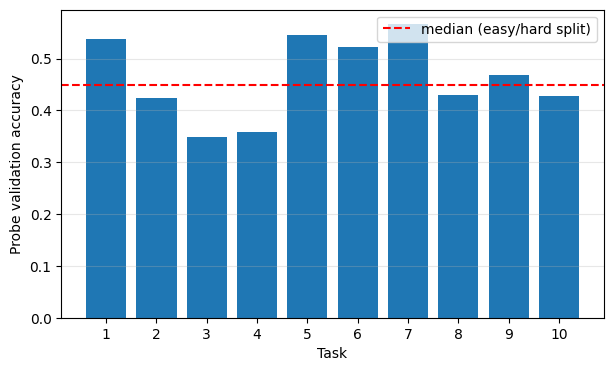

In [34]:
median = float(np.median(difficulty))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(np.arange(N_TASKS), difficulty)
ax.axhline(median, color="r", ls="--", label="Median (easy/hard split)")
ax.set_xticks(np.arange(N_TASKS))
ax.set_xticklabels([str(i + 1) for i in range(N_TASKS)])
ax.set_xlabel("Task")
ax.set_ylabel("Probe validation accuracy")
ax.grid(alpha=0.3, axis="y")
ax.legend()

PLOTS_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(PLOTS_DIR / "task_difficulty.png", dpi=150, bbox_inches="tight")
plt.show()

In [36]:
#Task Order

def generate_task_orders(difficulty, n_orders, seed):
    n = len(difficulty)
    ranked = sorted(range(n), key=lambda t: difficulty[t])
    hard, easy = ranked[: n // 2], ranked[n // 2:]
    rng = np.random.RandomState(seed)

    orders = []
    guard = 0
    while len(orders) < n_orders and guard < 1000:
        guard += 1
        h = list(rng.permutation(hard))
        e = list(rng.permutation(easy))
        order = []
        for i in range(max(len(h), len(e))):
            if i < len(h):
                order.append(int(h[i]))
            if i < len(e):
                order.append(int(e[i]))
        if order not in orders:
            orders.append(order)
    if len(orders) < n_orders:
        raise RuntimeError(f"Only produced {len(orders)} unique orders")
    return orders

task_orders = generate_task_orders(difficulty, N_ORDERS, SEED)
for k, order in enumerate(task_orders):
    print(f"Order {k} : {[t+1 for t in order]}")

Order 0 : [3, 9, 8, 5, 2, 1, 4, 7, 10, 6]
Order 1 : [2, 6, 4, 9, 3, 7, 8, 1, 10, 5]
Order 2 : [8, 6, 3, 1, 10, 9, 2, 7, 4, 5]
Order 3 : [3, 9, 8, 6, 10, 7, 4, 1, 2, 5]
Order 4 : [3, 1, 4, 5, 10, 6, 2, 9, 8, 7]
Order 5 : [4, 5, 3, 6, 10, 1, 2, 9, 8, 7]


In [40]:
payload = {
    "seed": SEED,
    "n_tasks": N_TASKS,
    "classes_per_task": CLASSES_PER_TASK,
    "class_to_task": class_to_task,
    "class_names_per_task": [[CLASS_NAMES[c] for c in cs] for cs in class_to_task],
    "task_orders": task_orders,
    "difficulty": difficulty,
    "difficulty_protocol": {
        "model": "ProbeCNN",
        "epochs": PROBE_EPOCHS,
        "lr": PROBE_LR,
        "measured_on": "validation",
        "note": "fixed identical budget per task; used only to rank tasks for interleaving (D5)",
    },
    "split_sizes": {
        f"task-{t+1}": {s: int(len(splits[t][s]["labels_local"])) for s in ("train", "valid", "test")}
        for t in range(N_TASKS)
    },
    "config": {
        "seed": SEED, "n_tasks": N_TASKS, "classes_per_task": CLASSES_PER_TASK,
        "val_fraction": VAL_FRACTION, "n_orders": N_ORDERS, "image_size": IMAGE_SIZE,
        "batch_size": BATCH_SIZE, "num_workers": NUM_WORKERS,
    },
}
TASK_ORDER_JSON.write_text(json.dumps(payload, indent=2))
print("Wrote  ", TASK_ORDER_JSON)

zip_path = shutil.make_archive(str(ROOT / "Data" / "DL_Dataset"), "zip", PROCESSED_DIR)
print("Created", zip_path)

Wrote   /kaggle/working/Data/processed/task_order.json
Created /kaggle/working/Data/DL_Dataset.zip
